# Laboratorio 1 - Exploración, preparación y regresión lineal

Integrantes:
- Juan Felipe Sáenz- 202311148
- Tomas Aguilera-202321962


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Carga de datos del laboratorio

In [3]:
df = pd.read_csv("Datos Lab 1.csv")
df_test = pd.read_csv("Datos Test Lab 1.csv")

# Revisamos las primeras filas de los datos

In [4]:
# Miramos los primeros 5 datos de los archivos
df.head()

,fecha,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,...,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,estacion_anio,mes,sector_viento,temp_max_manana
0,2009-01-01,999.1456,996.50,1000.87,1.3993,0.910860,0.875000,94.8,1.7650,0.7786,...,-0.3618,-0.0223,183.5308,143.0,2009.0,1.0,invierno,January,S,-2.12
1,2009-01-02,999.6006,997.93,1002.65,1.5039,0.920868,86.600000,96.3,2.7588,1.4195,...,0.4267,0.3689,40.8436,144.0,2009.0,2.0,invierno,JULY,NE,-0.82
2,2009-01-03,998.5486,993.05,1002.49,3.1304,76.458100,48.390000,93.9,15.1796,1.2509,...,-0.6993,-0.5268,216.9916,144.0,2009.0,3.0,invierno,January,SO,-0.63
3,2009-01-04,988.5107,985.12,992.93,2.3223,89.417400,97.946704,NaN,4.4904,1.7204,...,-1.1268,-1.0413,222.7419,144.0,2009.0,4.0,invierno,JANUARY,SO,-1.44
4,2009-01-05,990.4057,NaN,997.54,4.2315,86.260400,74.600000,93.2,5.3922,3.8003,...,2.6275,0.2874,6.2418,NaN,2009.0,5.0,East,January,N,-10.88


In [5]:
#Mediante una tupla, revisamos la cantidad de filas y columnas de esta manera (filas, columnas)
print (df.shape)

(2576, 27)


In [6]:
#Revisamos las etiquetas de las columnas
print (df.columns)

Index(['fecha', 'presion_media', 'presion_min', 'presion_max', 'presion_desv',
       'humedad_media', 'humedad_min', 'humedad_max', 'humedad_desv',
       'viento_media', 'viento_min', 'viento_max', 'viento_desv',
       'rafaga_media', 'rafaga_min', 'rafaga_max', 'rafaga_desv',
       'viento_norte', 'viento_este', 'direccion_viento', 'registros_del_dia',
       'anio', 'dia_del_anio', 'estacion_anio', 'mes', 'sector_viento',
       'temp_max_manana'],
      dtype='str')


# Exploración de los datos

In [7]:
#Revisamos el tipo de dato de cada variable y la cantidad de valores no nulos
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2576 entries, 0 to 2575
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   fecha              2504 non-null   str    
 1   presion_media      2501 non-null   float64
 2   presion_min        2502 non-null   float64
 3   presion_max        2512 non-null   float64
 4   presion_desv       2496 non-null   float64
 5   humedad_media      2502 non-null   float64
 6   humedad_min        2496 non-null   float64
 7   humedad_max        2490 non-null   float64
 8   humedad_desv       2515 non-null   float64
 9   viento_media       2490 non-null   float64
 10  viento_min         2485 non-null   float64
 11  viento_max         2495 non-null   float64
 12  viento_desv        2504 non-null   float64
 13  rafaga_media       2498 non-null   float64
 14  rafaga_min         2504 non-null   float64
 15  rafaga_max         2503 non-null   float64
 16  rafaga_desv        2497 non-null   

In [8]:
# Revisamos las principales estadísticas descriptivas de las variables númericas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
presion_media,2501.0,1010.494271,435.334494,948.996000,984.287800,989.452800,994.469000,9939.918000
presion_min,2502.0,986.684409,8.927138,913.600000,981.371333,987.070000,992.567500,1012.320198
presion_max,2512.0,991.704244,7.726906,951.940000,987.070000,991.935000,996.782500,1013.940000
presion_desv,2496.0,1.752041,1.215931,0.226900,0.899050,1.444550,2.254800,12.397500
humedad_media,2502.0,52.413586,35.975384,0.004663,0.869060,68.558100,80.562600,100.000000
humedad_min,2496.0,45.094067,30.196163,0.237700,1.011790,49.670000,67.665000,103.311405
humedad_max,2490.0,90.236582,10.647237,27.020000,88.025000,93.300000,96.600000,100.000000
humedad_desv,2515.0,10.606821,5.481338,0.000000,6.082100,10.199800,14.722200,26.341600
viento_media,2490.0,3.814103,3.307402,0.000000,1.655350,2.463400,4.880505,24.753600
viento_min,2485.0,1.417799,3.960650,0.000000,0.230000,0.440000,0.960000,45.184956


In [9]:
# Revisamos la cantidad de valores faltantes por variable
# Construimos una tabla con la cantidad y porcentaje de valores faltantes
faltantes = pd.DataFrame({
    "Cantidad": df.isnull().sum(),
    "Porcentaje": df.isnull().mean() * 100
})

faltantes = faltantes[faltantes["Cantidad"] > 0]
faltantes.sort_values("Porcentaje", ascending=False)

,Cantidad,Porcentaje
temp_max_manana,95,3.687888
viento_min,91,3.532609
estacion_anio,88,3.416149
mes,88,3.416149
anio,86,3.338509
humedad_max,86,3.338509
viento_media,86,3.338509
viento_max,81,3.144410
humedad_min,80,3.105590
viento_norte,80,3.105590


Se identificaron valores faltantes en diferentes variables del conjunto de datos. 
Estos serán tratados posteriormente durante la etapa de preparación, teniendo en cuenta
el tipo de variable y evitando modificar los datos antes de realizar la división entre
entrenamiento y prueba.

In [10]:
# Revisamos si existen registros duplicados
df.duplicated().sum()

np.int64(4)

In [11]:
#Revisamos cuales son los duplicados
df[df.duplicated()]

,fecha,presion_media,presion_min,presion_max,presion_desv,humedad_media,humedad_min,humedad_max,humedad_desv,viento_media,...,viento_norte,viento_este,direccion_viento,registros_del_dia,anio,dia_del_anio,estacion_anio,mes,sector_viento,temp_max_manana
2556,2013-04-20,1000.4455,998.46,1002.49,1.1632,60.748100,45.71,82.0,10.9518,17.65908,...,4.1573,2.5121,31.1426,144.0,2013.0,110.0,primavera,JANUARY,NE,61.412
2559,2012-11-13,1005.3724,1002.77,1006.81,1.0690,88.175500,58.28,99.1,12.6853,4.07916,...,-0.9230,-0.2193,193.3681,144.0,2012.0,318.0,otono,abril,S,44.852
2563,2009-01-22,9784.1150,971.48,983.54,3.9853,86.731100,69.11,97.6,9.7926,10.09692,...,-2.7229,-0.1899,183.9897,144.0,2009.0,22.0,verano,octubre,S,5.770
2565,2013-02-08,984.6369,983.06,987.49,1.3454,0.886056,0.76,96.8,4.6160,NaN,...,0.0254,-0.2613,275.5529,144.0,2013.0,39.0,verano,Sep,O,-0.600


Se encontraron registros duplicados en el conjunto de datos. Estos serán tratados
posteriormente durante la etapa de preparación para evitar que observaciones repetidas
afecten el entrenamiento del modelo.

In [12]:
#Revisamos los valores presentes en la variable estación del año
df["estacion_anio"].value_counts(dropna=False)

estacion_anio
primavera               517
invierno                511
otono                   500
verano                  487
NaN                      88
Inverano                 71
Estacion_Desconocida     63
VERANO_INVIERNO          60
East                     48
VERANO                   19
autumn                   18
primaveraa               17
berano                   17
fall                     15
winter                   15
verno                    14
Otoño                    12
otoño                    11
invernio                 11
Primavera                10
PRIMAVERA                10
invierno                  9
INVIERNO                  9
Verano                    9
Invierno                  9
OTONO                     8
primav                    6
spring                    6
summer                    6
Name: count, dtype: int64

In [13]:
#Revisamos los valores presentes en la variable mes
df["mes"].value_counts(dropna=False)

mes
May           127
August        125
July          123
January       120
March         118
             ... 
april          16
septiembre     16
junio          16
Jan            13
OCTOBER        13
Name: count, Length: 62, dtype: int64

In [14]:
#Revisamos los valores presentes en la variable sector del viento
df["sector_viento"].value_counts(dropna=False)

sector_viento
SO           695
S            519
NE           424
O            308
N            124
E             77
NaN           71
SE            66
NO            42
Suroeste      29
so            26
SOUTHWEST     24
s             20
South         19
ne            19
NORTHEAST     17
Sur           16
Noreste       12
o              8
SOUTH          8
NORTH          6
no             6
West           5
WEST           5
North          4
East           4
EAST           4
Sureste        3
Oeste          3
Noroeste       3
SOUTHEAST      3
Norte          3
Este           2
NORTHWEST      1
Name: count, dtype: int64

Las variables categóricas presentan inconsistencias en la representación de algunas
categorías. Se observan diferencias de idioma, uso de mayúsculas y minúsculas,
espacios y posibles errores de escritura. Por lo tanto, será necesario normalizar
estas variables durante la preparación de los datos.

In [15]:
#Revisamos si Python está interpretando la fecha de manera correcta
df["fecha"]=pd.to_datetime(df["fecha"],errors="coerce")

In [16]:
#Revisamos si alguna fecha no pudo ser interpretada
df["fecha"].isnull().sum()

np.int64(72)

In [17]:
#Revisamos el rango temporal de los datos
print("Fecha mínima:",df["fecha"].min())
print("Fecha máxima:",df["fecha"].max())

Fecha mínima: 2009-01-01 00:00:00
Fecha máxima: 2015-12-31 00:00:00


In [18]:
# Verificamos si el año registrado coincide con el año obtenido a partir de la fecha
mask = df["fecha"].notna() & df["anio"].notna()

inconsistencias_anio = (
    df.loc[mask, "fecha"].dt.year != df.loc[mask, "anio"]
).sum()

print("Inconsistencias en el año:", inconsistencias_anio)

Inconsistencias en el año: 0


In [19]:
# Verificamos si el día del año coincide con el calculado a partir de la fecha
mask = df["fecha"].notna() & df["dia_del_anio"].notna()

inconsistencias_dia = (
    df.loc[mask, "fecha"].dt.dayofyear != df.loc[mask, "dia_del_anio"]
).sum()

print("Inconsistencias en el día del año:", inconsistencias_dia)

Inconsistencias en el día del año: 0


In [20]:
# Obtenemos el mes directamente desde la fecha para compararlo con la variable mes
df["mes_fecha"] = df["fecha"].dt.month

df[["fecha", "mes", "mes_fecha"]].head(20)

,fecha,mes,mes_fecha
0,2009-01-01,January,1.0
1,2009-01-02,JULY,1.0
2,2009-01-03,January,1.0
3,2009-01-04,JANUARY,1.0
4,2009-01-05,January,1.0
5,2009-01-06,January,1.0
6,2009-01-07,January,1.0
7,2009-01-08,May,1.0
8,2009-01-09,Enero,1.0
9,2009-01-10,NaN,1.0


In [21]:
# Eliminamos la variable auxiliar utilizada únicamente para la exploración
df.drop(columns=["mes_fecha"], inplace=True)

La variable "mes" prfesenta diferencias tanfo en la forma de escribir las categorias, como en posibles inconsistencias respecto a la fecha registrada, esto debido a que el mes puede obtenerse directamente a partir de la fecha, esta situación será considerada en la ingeniería de características

In [22]:
# Revisamos las estadísticas de la variable objetivo
df["temp_max_manana"].describe()

count    2481.000000
mean       13.863309
std         9.296199
min       -15.230000
25%         7.310000
50%        14.310000
75%        20.460000
max        63.050000
Name: temp_max_manana, dtype: float64

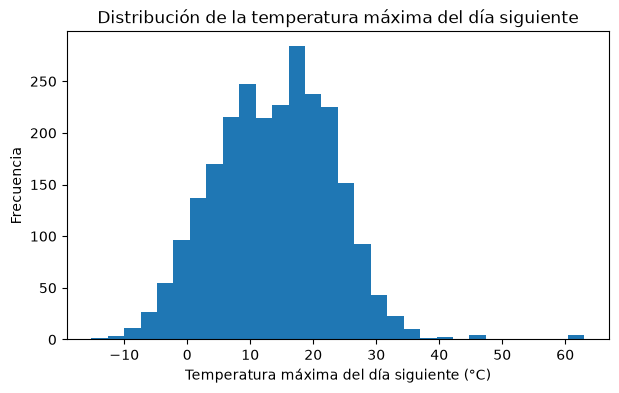

In [23]:
# Visualizamos la distribución de la temperatura máxima del día siguiente
plt.figure(figsize=(7, 4))
plt.hist(df["temp_max_manana"].dropna(), bins=30)

plt.xlabel("Temperatura máxima del día siguiente (°C)")
plt.ylabel("Frecuencia")
plt.title("Distribución de la temperatura máxima del día siguiente")

plt.show()

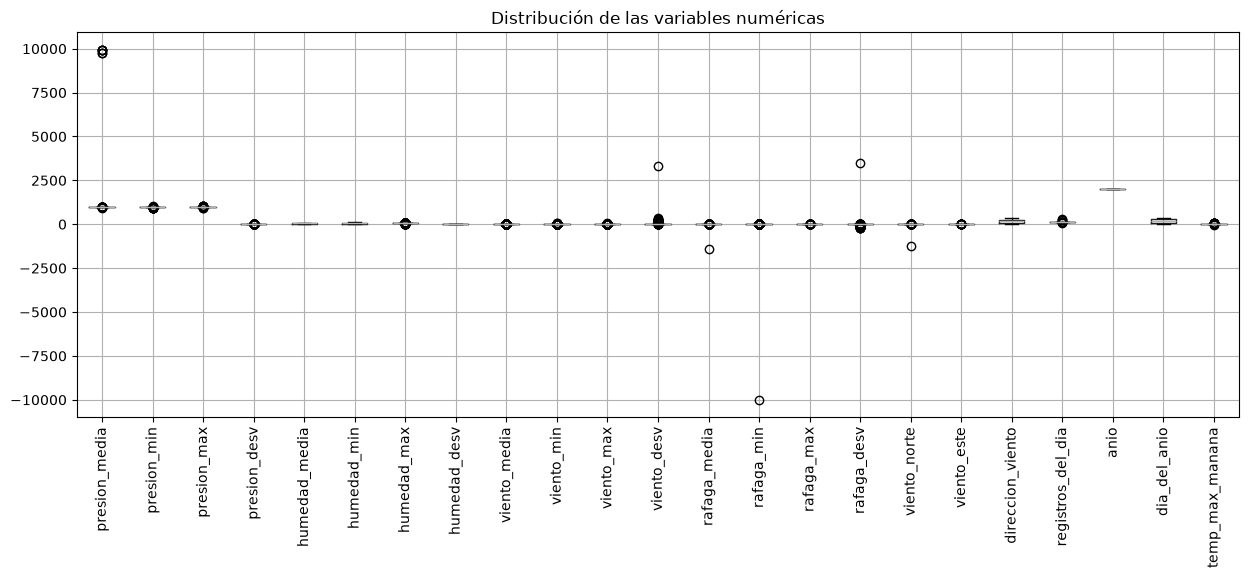

In [24]:
# Visualizamos posibles valores atípicos en las variables numéricas
columnas_numericas = df.select_dtypes(include=np.number).columns

df[columnas_numericas].boxplot(
    figsize=(15, 5),
    rot=90
)

plt.title("Distribución de las variables numéricas")
plt.show()

Revisamos  las variables sospechosas de manera individual

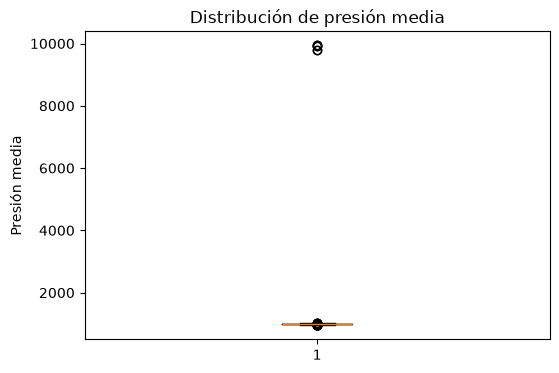

In [25]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["presion_media"].dropna())
plt.ylabel("Presión media")
plt.title("Distribución de presión media")
plt.show()

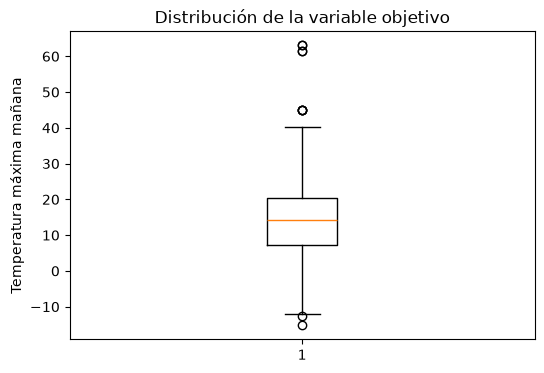

In [26]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["temp_max_manana"].dropna())
plt.ylabel("Temperatura máxima mañana")
plt.title("Distribución de la variable objetivo")
plt.show()

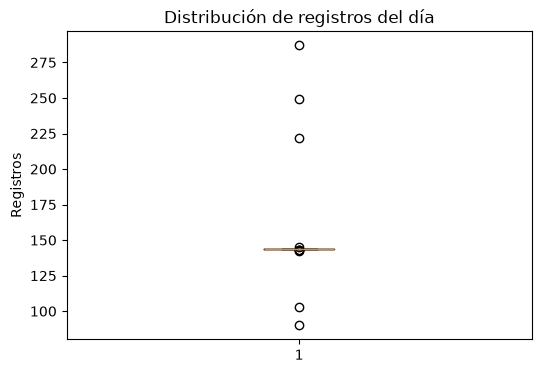

In [27]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["registros_del_dia"].dropna())
plt.ylabel("Registros")
plt.title("Distribución de registros del día")
plt.show()

In [28]:
#Revisamos valores de humedad minima que se encuentren fuera del rango ideal
df[
    (df["humedad_min"]<0) | (df["humedad_min"]>100)
].count().sum()

np.int64(604)

In [29]:
# Revisamos valores de dirección del viento fuera del rango esperado
df[
    (df["direccion_viento"] < 0) |
    (df["direccion_viento"] > 360)
].count().sum()

np.int64(0)

In [30]:
#Revisamos la distribución de la cantidad de registros disponibles por día
df["registros_del_dia"].describe()

count    2499.000000
mean      144.090836
std         4.107365
min        90.000000
25%       144.000000
50%       144.000000
75%       144.000000
max       287.000000
Name: registros_del_dia, dtype: float64

In [31]:
#Identificamos días con una cantidad superior a 144 registros( lo esperado)
df[df["registros_del_dia"]>144][["fecha","registros_del_dia"]]


,fecha,registros_del_dia
546,2010-07-01,287.0
547,2010-07-02,145.0
1904,2014-03-20,222.0
1905,2014-03-21,249.0


In [32]:
#Calculamos la correlación de las variables númericas con la variable objetivo

correlaciones=(
    df.select_dtypes(include=np.number).corr()["temp_max_manana"].sort_values(ascending=False)
)

correlaciones

temp_max_manana      1.000000
humedad_desv         0.571459
dia_del_anio         0.165812
presion_min          0.141860
anio                 0.092718
presion_max          0.070861
viento_desv          0.040129
viento_max           0.031348
rafaga_max           0.030527
registros_del_dia    0.025923
viento_este          0.015941
direccion_viento     0.007824
rafaga_desv         -0.007027
rafaga_min          -0.019087
viento_norte        -0.020881
rafaga_media        -0.024158
presion_media       -0.032249
viento_media        -0.035994
viento_min          -0.039749
humedad_media       -0.098139
humedad_max         -0.155211
presion_desv        -0.199890
humedad_min         -0.203226
Name: temp_max_manana, dtype: float64

In [33]:
# Seleccionamos las variables con mayor correlación absoluta con la variable objetivo
top_variables = (
    correlaciones
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index
)

corr_top = df[top_variables].corr()

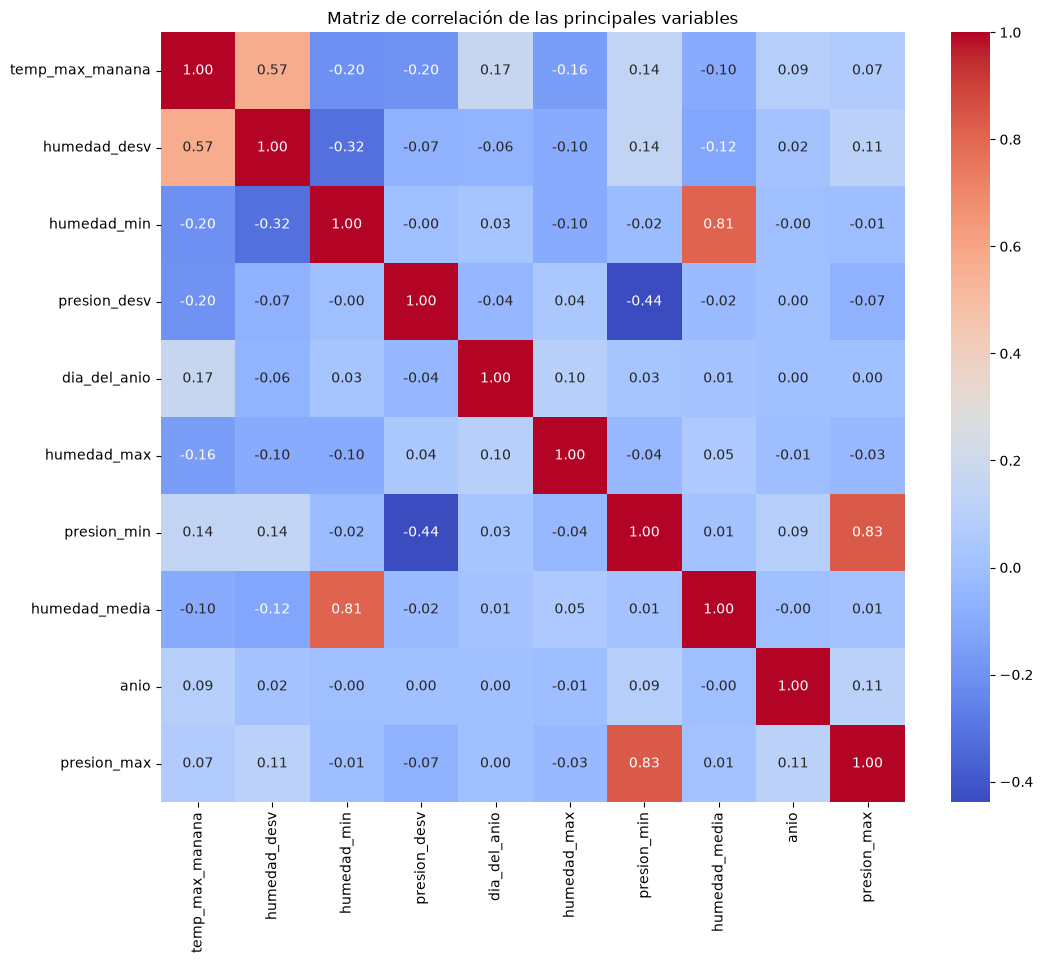

In [34]:
import seaborn as sns

plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_top,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Matriz de correlación de las principales variables")
plt.show()

###Hallazgos de la exploración

La exploración permitió identificar valores faltantes en diferentes variables y en registros duplicados, se encintraron inconsistencias en la representación de variables como "esatcion_anio", "mes" y "sector_viento".
La variables temporales presentan redundancia en la información, dado que algunas vienen directamente de fecha
Finalmente, se encontró que algunas variables numericas presentan valores atípicos o fuera de los rangos, por lo que estos casos deben ser considerados en la preparación de datos

# Preparación de los datos

In [35]:
# Creamos una copia para realizar la preparación de los datos
df_modelo = df.copy()

In [36]:
# Eliminamos registros sin valor en la variable objetivo
df_modelo = df_modelo.dropna(subset=["temp_max_manana"])

df_modelo.shape

(2481, 27)

In [37]:
# Eliminamos registros completamente duplicados
df_modelo = df_modelo.drop_duplicates()

df_modelo.shape

(2477, 27)

In [38]:
#Comprobamos la no existencia de duplicados
df_modelo.duplicated().sum()

np.int64(0)

In [39]:
# Separamos las variables predictoras y la variable objetivo
X = df_modelo.drop(columns=["temp_max_manana"])
y = df_modelo["temp_max_manana"]

print("X:", X.shape)
print("y:", y.shape)

X: (2477, 26)
y: (2477,)


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

print("Entrenamiento:", X_train.shape)
print("Test:", X_test.shape)

Entrenamiento: (1857, 26)
Test: (620, 26)


Se reservó el 25% de los datos para evaluación y se utilizó "random_state=42" , de acuerdo con las condiciones establecidas para el laboratorio.

## Modelo 1 - Variables numéricas

Como primera estrategia se construirá un modelo utilizando únicamente las variables numéricas. Las variables categóricas y la fecha se excluyen inicialmente debido a las inconsistencias identificadas durante la exploración. Los valores faltantes serán imputados mediante la mediana dentro de un pipeline.

In [41]:
# Seleccionamos variables numéricas
columnas_numericas = X_train.select_dtypes(include=np.number).columns.tolist()

columnas_numericas

['presion_media',
 'presion_min',
 'presion_max',
 'presion_desv',
 'humedad_media',
 'humedad_min',
 'humedad_max',
 'humedad_desv',
 'viento_media',
 'viento_min',
 'viento_max',
 'viento_desv',
 'rafaga_media',
 'rafaga_min',
 'rafaga_max',
 'rafaga_desv',
 'viento_norte',
 'viento_este',
 'direccion_viento',
 'registros_del_dia',
 'anio',
 'dia_del_anio']

In [42]:
pipeline_modelo_1 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("regresion", LinearRegression())
])
pipeline_modelo_1.fit(
    X_train[columnas_numericas],
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacion', ...), ('regresion', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['presion_media','presion_min','presion_max',...,'registros_del_dia', 'anio','dia_del_anio']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for string

In [43]:
#Realizamos predicciones del Modelo 1
pred_modelo_1 = pipeline_modelo_1.predict(
    X_test[columnas_numericas]
)

In [44]:
rmse_1 = np.sqrt(mean_squared_error(y_test, pred_modelo_1))
mae_1 = mean_absolute_error(y_test, pred_modelo_1)
r2_1 = r2_score(y_test, pred_modelo_1)

print("RMSE:", rmse_1)
print("MAE:", mae_1)
print("R²:", r2_1)

RMSE: 7.148230847941255
MAE: 5.645431841020078
R²: 0.4033466172550345


In [45]:
#Comparamos prediccion vs valores reales
comparacion_1 = pd.DataFrame({
    "Real": y_test,
    "Predicción": pred_modelo_1
})

comparacion_1.head(10)

,Real,Predicción
1826,7.26,13.027488
269,17.49,20.215004
2156,2.93,12.658935
1044,7.68,12.829268
61,10.26,16.150026
2511,15.65,12.950670
2168,3.13,10.214494
1174,16.06,21.834388
970,15.59,21.799019
1144,3.98,8.957255


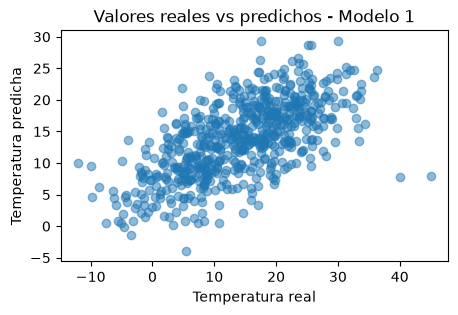

In [46]:
#Graficamos
plt.figure(figsize=(5, 3))

plt.scatter(y_test, pred_modelo_1, alpha=0.5)

plt.xlabel("Temperatura real")
plt.ylabel("Temperatura predicha")
plt.title("Valores reales vs predichos - Modelo 1")

plt.show()

In [47]:
#Guardamos el resultado
resultados = []

resultados.append({
    "Modelo": "Modelo 1 - Variables numéricas",
    "RMSE": rmse_1,
    "MAE": mae_1,
    "R2": r2_1
})

pd.DataFrame(resultados)

,Modelo,RMSE,MAE,R2
0,Modelo 1 - Variables numéricas,7.148231,5.645432,0.403347


## Modelo 2- Ingeniería de características temporales

En la segunda estrategia se incorpora ingeniería de características a partir de "fecha". Debido a las inconsistencias encontradas en la variable "mes", la información temporal se obtiene directamente de la fecha registrada. Además, se incorpora una representación cíclica del momento del año para permitir que el modelo represente mejor la estacionalidad

In [48]:
#Hacemos copias
X_train_2 = X_train.copy()
X_test_2 = X_test.copy()

In [49]:
#Nos aseguramos de que fecha sea datetime
X_train_2["fecha"] = pd.to_datetime(X_train_2["fecha"])
X_test_2["fecha"] = pd.to_datetime(X_test_2["fecha"])

#Creamos el mes correcto
X_train_2["mes_fecha"] = X_train_2["fecha"].dt.month
X_test_2["mes_fecha"] = X_test_2["fecha"].dt.month

#Creamos una representación del día del año
X_train_2["dia_sin"] = np.sin(
    2 * np.pi * X_train_2["fecha"].dt.dayofyear / 365.25
)

X_train_2["dia_cos"] = np.cos(
    2 * np.pi * X_train_2["fecha"].dt.dayofyear / 365.25
)

X_test_2["dia_sin"] = np.sin(
    2 * np.pi * X_test_2["fecha"].dt.dayofyear / 365.25
)

X_test_2["dia_cos"] = np.cos(
    2 * np.pi * X_test_2["fecha"].dt.dayofyear / 365.25
)

In [50]:
# Eliminamos columnas categóricas inconsistentes
columnas_eliminar_2 = [
    "fecha",
    "mes",
    "estacion_anio",
    "sector_viento"
]

X_train_2 = X_train_2.drop(columns=columnas_eliminar_2, errors="ignore")
X_test_2 = X_test_2.drop(columns=columnas_eliminar_2, errors="ignore")

# Verificamos que solo queden variables numéricas
X_train_2.dtypes

presion_media        float64
presion_min          float64
presion_max          float64
presion_desv         float64
humedad_media        float64
humedad_min          float64
humedad_max          float64
humedad_desv         float64
viento_media         float64
viento_min           float64
viento_max           float64
viento_desv          float64
rafaga_media         float64
rafaga_min           float64
rafaga_max           float64
rafaga_desv          float64
viento_norte         float64
viento_este          float64
direccion_viento     float64
registros_del_dia    float64
anio                 float64
dia_del_anio         float64
mes_fecha            float64
dia_sin              float64
dia_cos              float64
dtype: object

In [51]:
X_train_2.select_dtypes(exclude=np.number).columns

Index([], dtype='str')

In [52]:
#Verificamos que las columnas mes_fecha,dia_sin,dia_cos hayan quedado creadas
X_train_2.columns

Index(['presion_media', 'presion_min', 'presion_max', 'presion_desv',
       'humedad_media', 'humedad_min', 'humedad_max', 'humedad_desv',
       'viento_media', 'viento_min', 'viento_max', 'viento_desv',
       'rafaga_media', 'rafaga_min', 'rafaga_max', 'rafaga_desv',
       'viento_norte', 'viento_este', 'direccion_viento', 'registros_del_dia',
       'anio', 'dia_del_anio', 'mes_fecha', 'dia_sin', 'dia_cos'],
      dtype='str')

In [53]:
X_train_2.columns

Index(['presion_media', 'presion_min', 'presion_max', 'presion_desv',
       'humedad_media', 'humedad_min', 'humedad_max', 'humedad_desv',
       'viento_media', 'viento_min', 'viento_max', 'viento_desv',
       'rafaga_media', 'rafaga_min', 'rafaga_max', 'rafaga_desv',
       'viento_norte', 'viento_este', 'direccion_viento', 'registros_del_dia',
       'anio', 'dia_del_anio', 'mes_fecha', 'dia_sin', 'dia_cos'],
      dtype='str')

In [54]:
#Creamos Pipeline Módulo 2
pipeline_modelo_2 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("regresion", LinearRegression())
])

#Entrenamos
pipeline_modelo_2.fit(
    X_train_2,
    y_train
)

#Predecimos
pred_modelo_2 = pipeline_modelo_2.predict(
    X_test_2
)


In [55]:
#Evaluamos
rmse_2 = np.sqrt(mean_squared_error(y_test, pred_modelo_2))
mae_2 = mean_absolute_error(y_test, pred_modelo_2)
r2_2 = r2_score(y_test, pred_modelo_2)

print("RMSE:", rmse_2)
print("MAE:", mae_2)
print("R²:", r2_2)

RMSE: 4.895623619211338
MAE: 3.5912366056472336
R²: 0.7201398830314601


In [56]:
#Agregamos
resultados.append({
    "Modelo": "Modelo 2 - Ingeniería temporal",
    "RMSE": rmse_2,
    "MAE": mae_2,
    "R2": r2_2
})

In [57]:
#Comparamos
tabla_resultados = pd.DataFrame(resultados)

tabla_resultados

,Modelo,RMSE,MAE,R2
0,Modelo 1 - Variables numéricas,7.148231,5.645432,0.403347
1,Modelo 2 - Ingeniería temporal,4.895624,3.591237,0.720140


## Modelo 3 - Tratamiento de valores inconsistentes

 Como tercera estrategia se parte de la ingenieria temporal del modelo 2 y se incorpora un tratamiento adicional de valores inconsistentes detectados durante la exploración. Los valores encontradosfuera de los rangos físicamente posibles se reemplazan por valores faltantes para que posteriormente sean imputados mediante la mediana dentro del pipeline

In [58]:
# Creamos nuevas copias para el tercer modelo
X_train_3 = X_train.copy()
X_test_3 = X_test.copy()

#Convertimos fecha
X_train_3["fecha"] = pd.to_datetime(X_train_3["fecha"], errors="coerce")
X_test_3["fecha"] = pd.to_datetime(X_test_3["fecha"], errors="coerce")

#Ingeniería de características temporales
X_train_3["mes_fecha"] = X_train_3["fecha"].dt.month
X_test_3["mes_fecha"] = X_test_3["fecha"].dt.month

X_train_3["dia_sin"] = np.sin(
    2 * np.pi * X_train_3["fecha"].dt.dayofyear / 365.25
)

X_train_3["dia_cos"] = np.cos(
    2 * np.pi * X_train_3["fecha"].dt.dayofyear / 365.25
)

X_test_3["dia_sin"] = np.sin(
    2 * np.pi * X_test_3["fecha"].dt.dayofyear / 365.25
)

X_test_3["dia_cos"] = np.cos(
    2 * np.pi * X_test_3["fecha"].dt.dayofyear / 365.25
)


Tratamos valores físicamente inconsistentes, vamos a convertie en NaN aquellos valores que claramente violan una restricción lógica

In [59]:
#Humedad: entre 0 y 100
columnas_humedad = [
    "humedad_media",
    "humedad_min",
    "humedad_max"
]

for columna in columnas_humedad:
    X_train_3.loc[
        (X_train_3[columna] < 0) | (X_train_3[columna] > 100),
        columna
    ] = np.nan

    X_test_3.loc[
        (X_test_3[columna] < 0) | (X_test_3[columna] > 100),
        columna
    ] = np.nan

#Dirección del viento entre 0 y 360 grados
X_train_3.loc[
    (X_train_3["direccion_viento"] < 0) |
    (X_train_3["direccion_viento"] > 360),
    "direccion_viento"
] = np.nan

X_test_3.loc[
    (X_test_3["direccion_viento"] < 0) |
    (X_test_3["direccion_viento"] > 360),
    "direccion_viento"
] = np.nan


#Cantidad de registros diarios
X_train_3.loc[
    (X_train_3["registros_del_dia"] <= 0) |
    (X_train_3["registros_del_dia"] > 144),
    "registros_del_dia"
] = np.nan

X_test_3.loc[
    (X_test_3["registros_del_dia"] <= 0) |
    (X_test_3["registros_del_dia"] > 144),
    "registros_del_dia"
] = np.nan

#Variables que no deberían ser negativas
columnas_no_negativas = [
    "viento_media",
    "viento_min",
    "viento_max",
    "viento_desv",
    "rafaga_media",
    "rafaga_min",
    "rafaga_max",
    "rafaga_desv",
    "presion_desv",
    "humedad_desv"
]

for columna in columnas_no_negativas:
    X_train_3.loc[X_train_3[columna] < 0, columna] = np.nan
    X_test_3.loc[X_test_3[columna] < 0, columna] = np.nan

In [60]:
#Eliminamos variables categóricas inconsistentes
columnas_eliminar_3 = [
    "fecha",
    "mes",
    "estacion_anio",
    "sector_viento"
]

X_train_3 = X_train_3.drop(
    columns=columnas_eliminar_3,
    errors="ignore"
)

X_test_3 = X_test_3.drop(
    columns=columnas_eliminar_3,
    errors="ignore"
)

In [61]:
#Comprobación
X_train_3.select_dtypes(exclude=np.number).columns

Index([], dtype='str')

# Entrenamiento del modelo 3

In [62]:
pipeline_modelo_3 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("regresion", LinearRegression())
])

In [63]:
pipeline_modelo_3.fit(
    X_train_3,
    y_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacion', ...), ('regresion', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](25,)","['presion_media','presion_min','presion_max',...,'mes_fecha','dia_sin', 'dia_cos']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,25
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or objec

In [64]:
#Predecimos
pred_modelo_3 = pipeline_modelo_3.predict(
    X_test_3
)

In [65]:
#Evaluamos
rmse_3 = np.sqrt(
    mean_squared_error(y_test, pred_modelo_3)
)

mae_3 = mean_absolute_error(
    y_test,
    pred_modelo_3
)

r2_3 = r2_score(
    y_test,
    pred_modelo_3
)

print("RMSE:", rmse_3)
print("MAE:", mae_3)
print("R²:", r2_3)

RMSE: 4.867908302269602
MAE: 3.5613968811297876
R²: 0.7232996260897626


In [66]:
#Agregamos los resultados obtenidos
resultados.append({
    "Modelo": "Modelo 3 - Limpieza e ingeniería temporal",
    "RMSE": rmse_3,
    "MAE": mae_3,
    "R2": r2_3
})

## Comparación entre los tres modelos

In [67]:
tabla_resultados = pd.DataFrame(resultados)

tabla_resultados = tabla_resultados.sort_values(
    by="RMSE"
).reset_index(drop=True)

tabla_resultados

,Modelo,RMSE,MAE,R2
0,Modelo 3 - Limpieza e ingeniería temporal,4.867908,3.561397,0.723300
1,Modelo 2 - Ingeniería temporal,4.895624,3.591237,0.720140
2,Modelo 1 - Variables numéricas,7.148231,5.645432,0.403347


# Creamos la tabla definitiva con los 2 mejores

In [68]:
dos_mejores_modelos = tabla_resultados.head(2)

dos_mejores_modelos

,Modelo,RMSE,MAE,R2
0,Modelo 3 - Limpieza e ingeniería temporal,4.867908,3.561397,0.72330
1,Modelo 2 - Ingeniería temporal,4.895624,3.591237,0.72014


### Comparación de modelos

Se evaluaron tres estrategias de preparación utilizando regresión lineal. Para la comparación final se seleccionan los dos modelos con menor RMSE sobre el conjunto de prueba. Como métricas complementarias también se consideran el MAE y el R².

## Gráfico comparativo de RMSE

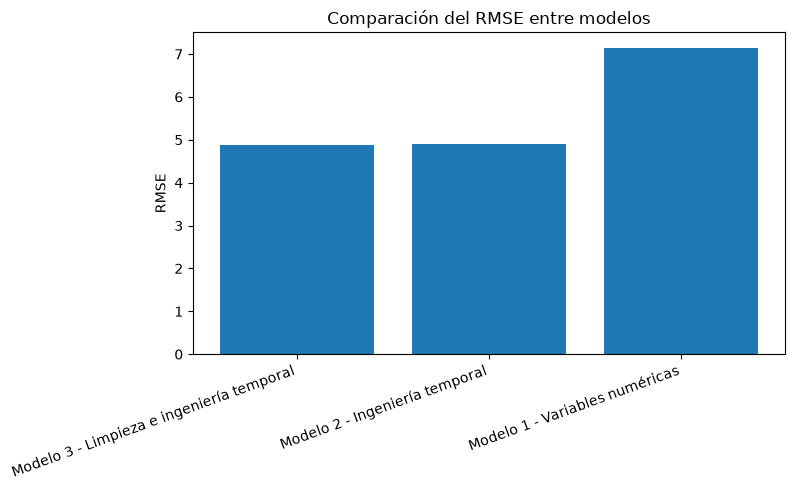

In [69]:
plt.figure(figsize=(8, 5))

plt.bar(
    tabla_resultados["Modelo"],
    tabla_resultados["RMSE"]
)

plt.ylabel("RMSE")
plt.title("Comparación del RMSE entre modelos")
plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

## Elección del mejor modelo


In [70]:
mejor_resultado = tabla_resultados.iloc[0]

print("Mejor modelo:", mejor_resultado["Modelo"])
print("RMSE:", mejor_resultado["RMSE"])
print("MAE:", mejor_resultado["MAE"])
print("R²:", mejor_resultado["R2"])

Mejor modelo: Modelo 3 - Limpieza e ingeniería temporal
RMSE: 4.867908302269602
MAE: 3.5613968811297876
R²: 0.7232996260897626


### Selección del mejor modelo

De acuerdo con los resultados obtenidos sobre el conjunto de prueba, el modelo con mejor desempeño fue **[NOMBRE]**, al obtener el menor RMSE. Adicionalmente, se tuvieron en cuenta los valores de MAE y R² para complementar la evaluación del desempeño predictivo.

In [71]:
mejor_modelo = pipeline_modelo_3
mejor_X_train = X_train_3
mejor_X_test = X_test_3
mejor_pred = pred_modelo_3